<a href="https://colab.research.google.com/github/Vedantsonawane-ngl/DS-experiments/blob/main/DVMAssignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Generate Mock Sales Data in Multiple Formats
We will create synthetic sales data containing overlapping transactions across three formats: CSV, Excel, and JSON.

In [1]:
import pandas as pd
import numpy as np
import json

# Create some consistent dummy data
data_csv = {
    'transaction_id': [101, 102, 103, 104],
    'date': ['2023-10-01', '2023-10-02', '2023-10-03', None],
    'product': ['Laptop', 'Mouse', 'Keyboard', 'Monitor'],
    'quantity': [1, 2, 1, 1],
    'price': [1200.0, 25.0, 75.0, 300.0]
}

data_excel = {
    'transaction_id': [105, 106, 107, 101],  # 101 is a duplicate to handle later
    'date': ['2023-10-04', '2023-10-05', '2023-10-06', '2023-10-01'],
    'product': ['Headphones', 'Webcam', 'USB-C Cable', 'Laptop'],
    'quantity': [1, 1, 3, 1],
    'price': [150.0, 80.0, 15.0, 1200.0]
}

data_json = [
    {'transaction_id': 108, 'date': '2023-10-07', 'product': 'Desk Lamp', 'quantity': 2, 'price': 45.0},
    {'transaction_id': 109, 'date': '2023-10-08', 'product': 'Chair', 'quantity': 1, 'price': 250.0},
    {'transaction_id': 110, 'date': None, 'product': 'Notebook', 'quantity': 5, 'price': 5.0}
]

# Convert to DataFrames and save to files
df_csv = pd.DataFrame(data_csv)
df_excel = pd.DataFrame(data_excel)

df_csv.to_csv('sales_data.csv', index=False)
df_excel.to_excel('sales_data.xlsx', index=False)
with open('sales_data.json', 'w') as f:
    json.dump(data_json, f)

print("Generated and saved 'sales_data.csv', 'sales_data.xlsx', and 'sales_data.json'.")

Generated and saved 'sales_data.csv', 'sales_data.xlsx', and 'sales_data.json'.


# Task 2: Load the Datasets
Now we will load the datasets into pandas DataFrames and print their basic properties to inspect their structures.

In [2]:
# Load files
df_csv_loaded = pd.read_csv('sales_data.csv')
df_excel_loaded = pd.read_excel('sales_data.xlsx')
df_json_loaded = pd.read_json('sales_data.json')

print("--- CSV Sales Data ---")
display(df_csv_loaded)

print("\n--- Excel Sales Data ---")
display(df_excel_loaded)

print("\n--- JSON Sales Data ---")
display(df_json_loaded)

--- CSV Sales Data ---


,transaction_id,date,product,quantity,price
0,101,2023-10-01,Laptop,1,1200.0
1,102,2023-10-02,Mouse,2,25.0
2,103,2023-10-03,Keyboard,1,75.0
3,104,NaN,Monitor,1,300.0



--- Excel Sales Data ---


,transaction_id,date,product,quantity,price
0,105,2023-10-04,Headphones,1,150
1,106,2023-10-05,Webcam,1,80
2,107,2023-10-06,USB-C Cable,3,15
3,101,2023-10-01,Laptop,1,1200



--- JSON Sales Data ---


,transaction_id,date,product,quantity,price
0,108,2023-10-07,Desk Lamp,2,45
1,109,2023-10-08,Chair,1,250
2,110,NaT,Notebook,5,5


## Exploring User-Selected Dataset
We will load and explore the provided file `/content/Sales-Export_2019-2020.csv`.

In [3]:
# Load the user-provided CSV
user_sales_df = pd.read_csv('/content/Sales-Export_2019-2020.csv')

# Display basic info and first few rows
print("--- Dataset Information ---")
user_sales_df.info()

print("\n--- Missing Values Summary ---")
print(user_sales_df.isnull().sum())

print("\n--- First 5 Rows ---")
display(user_sales_df.head())

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   country            1000 non-null   object 
 1    order_value_EUR   1000 non-null   object 
 2    cost              1000 non-null   float64
 3   date               1000 non-null   object 
 4   category           1000 non-null   object 
 5   customer_name      1000 non-null   object 
 6   sales_manager      1000 non-null   object 
 7   sales_rep          1000 non-null   object 
 8   device_type        1000 non-null   object 
 9   order_id           1000 non-null   object 
dtypes: float64(1), object(9)
memory usage: 78.3+ KB

--- Missing Values Summary ---
country              0
 order_value_EUR     0
 cost                0
date                 0
category             0
customer_name        0
sales_manager        0
sales_rep            0
device_type          

,country,order_value_EUR,cost,date,category,customer_name,sales_manager,sales_rep,device_type,order_id
0,Sweden,"17,524.02",14122.61,2/12/2020,Books,Goldner-Dibbert,Maxie Marrow,Madelon Bront,Mobile,70-0511466
1,Finland,"116,563.40",92807.78,9/26/2019,Games,Hilll-Vandervort,Hube Corey,Wat Bowkley,Mobile,28-6585323
2,Portugal,"296,465.56",257480.34,7/11/2019,Clothing,Larkin-Collier,Celine Tumasian,Smitty Culverhouse,PC,58-7703341
3,Portugal,"74,532.02",59752.32,4/2/2020,Beauty,Hessel-Stiedemann,Celine Tumasian,Aurelie Wren,PC,14-6700183
4,Spain,"178,763.42",146621.76,12/22/2019,Games,Johns and Sons,Emalia Dinse,Bertha Walbrook,Tablet,15-8765160


## Tasks 3, 4 & 5: Data Cleaning and Data Transformation
We will clean the column names, format dates, and parse numerical figures to make the dataset ready for analytics.

In [4]:
# 1. Clean column names (strip leading/trailing whitespaces)
user_sales_df.columns = user_sales_df.columns.str.strip()

# 2. Clean 'order_value_EUR': remove commas and convert to float
user_sales_df['order_value_EUR'] = user_sales_df['order_value_EUR'].astype(str).str.replace(',', '').str.strip()
user_sales_df['order_value_EUR'] = pd.to_numeric(user_sales_df['order_value_EUR'], errors='coerce')

# 3. Convert 'date' column to datetime format
user_sales_df['date'] = pd.to_datetime(user_sales_df['date'], errors='coerce')

# 4. Check for and remove duplicate rows
duplicates_count = user_sales_df.duplicated().sum()
print(f"Number of duplicate rows removed: {duplicates_count}")
user_sales_df = user_sales_df.drop_duplicates()

# 5. Extract additional temporal features for analysis
user_sales_df['year_month'] = user_sales_df['date'].dt.to_period('M')
user_sales_df['year'] = user_sales_df['date'].dt.year

# Display cleaned dataset details
print("\n--- Cleaned Dataset Information ---")
user_sales_df.info()
display(user_sales_df.head())

Number of duplicate rows removed: 0

--- Cleaned Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   country          1000 non-null   object        
 1   order_value_EUR  1000 non-null   float64       
 2   cost             1000 non-null   float64       
 3   date             1000 non-null   datetime64[ns]
 4   category         1000 non-null   object        
 5   customer_name    1000 non-null   object        
 6   sales_manager    1000 non-null   object        
 7   sales_rep        1000 non-null   object        
 8   device_type      1000 non-null   object        
 9   order_id         1000 non-null   object        
 10  year_month       1000 non-null   period[M]     
 11  year             1000 non-null   int32         
dtypes: datetime64[ns](1), float64(2), int32(1), object(7), period[M](1)
memory

,country,order_value_EUR,cost,date,category,customer_name,sales_manager,sales_rep,device_type,order_id,year_month,year
0,Sweden,17524.02,14122.61,2020-02-12,Books,Goldner-Dibbert,Maxie Marrow,Madelon Bront,Mobile,70-0511466,2020-02,2020
1,Finland,116563.40,92807.78,2019-09-26,Games,Hilll-Vandervort,Hube Corey,Wat Bowkley,Mobile,28-6585323,2019-09,2019
2,Portugal,296465.56,257480.34,2019-07-11,Clothing,Larkin-Collier,Celine Tumasian,Smitty Culverhouse,PC,58-7703341,2019-07,2019
3,Portugal,74532.02,59752.32,2020-04-02,Beauty,Hessel-Stiedemann,Celine Tumasian,Aurelie Wren,PC,14-6700183,2020-04,2020
4,Spain,178763.42,146621.76,2019-12-22,Games,Johns and Sons,Emalia Dinse,Bertha Walbrook,Tablet,15-8765160,2019-12,2019


## Tasks 6 & 7: Descriptive Statistics, Aggregation & Visualizations
We will perform descriptive analysis, calculate key sales metrics, and create visualizations to understand the performance.

--- Descriptive Statistics ---


,order_value_EUR,cost
count,1000.000000,1000.000000
mean,113361.738710,94369.310990
std,61775.335675,51540.020934
min,15100.570000,12113.680000
25%,65310.862500,54247.957500
50%,105419.425000,87094.760000
75%,151192.642500,125570.837500
max,383996.760000,304701.430000


Total Sales (EUR): 113,361,738.71
Total Cost (EUR): 94,369,310.99
Total Profit (EUR): 18,992,427.72


/tmp/ipykernel_3694/2059048639.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sales_by_category, x='order_value_EUR', y='category', palette='viridis')


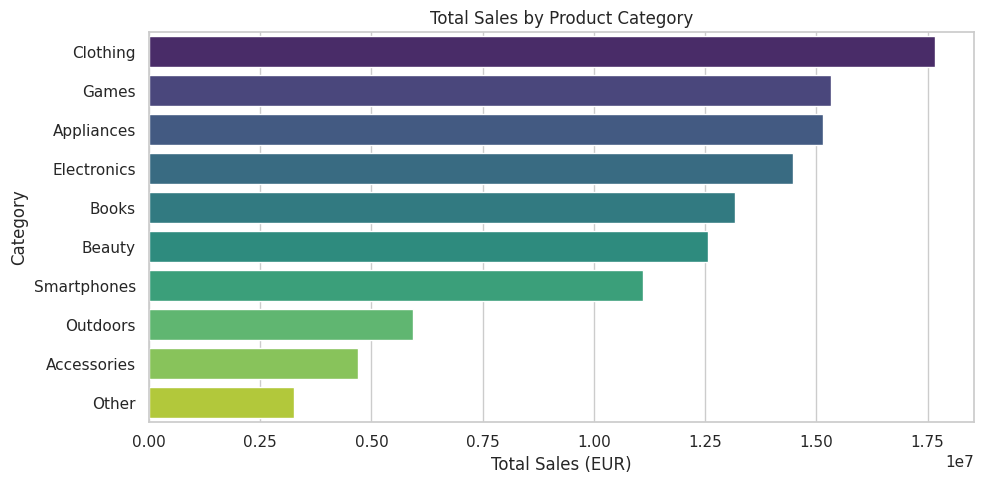

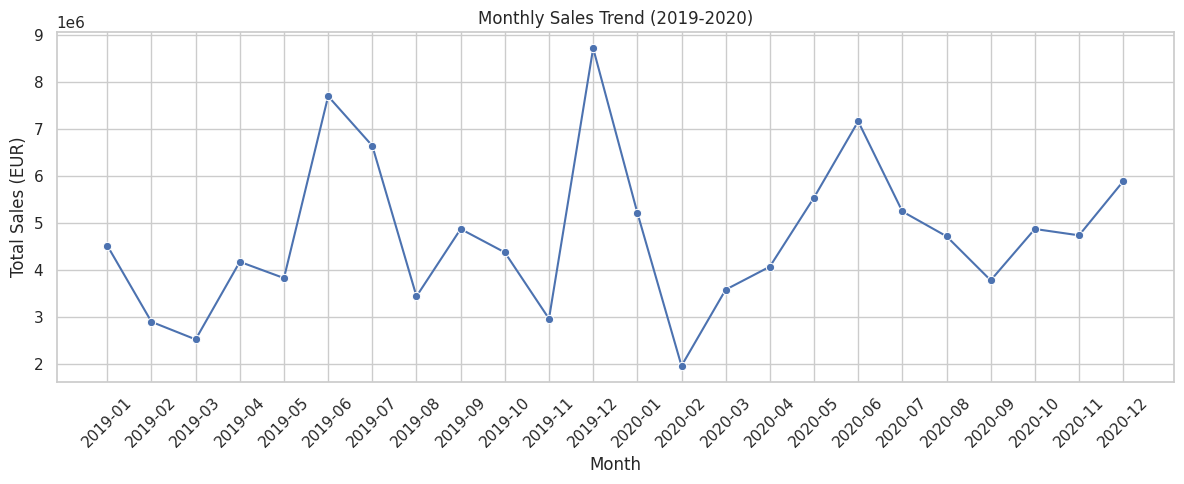

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Descriptive Statistics
print("--- Descriptive Statistics ---")
display(user_sales_df[['order_value_EUR', 'cost']].describe())

# Total metrics
total_sales = user_sales_df['order_value_EUR'].sum()
total_cost = user_sales_df['cost'].sum()
total_profit = total_sales - total_cost
print(f"Total Sales (EUR): {total_sales:,.2f}")
print(f"Total Cost (EUR): {total_cost:,.2f}")
print(f"Total Profit (EUR): {total_profit:,.2f}")

# Set seaborn style
sns.set_theme(style="whitegrid")

# Plot 1: Sales Distribution by Category
plt.figure(figsize=(10, 5))
sales_by_category = user_sales_df.groupby('category')['order_value_EUR'].sum().reset_index().sort_values(by='order_value_EUR', ascending=False)
sns.barplot(data=sales_by_category, x='order_value_EUR', y='category', palette='viridis')
plt.title('Total Sales by Product Category')
plt.xlabel('Total Sales (EUR)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

# Plot 2: Sales Trend over Time (Monthly)
plt.figure(figsize=(12, 5))
sales_trend = user_sales_df.groupby('year_month')['order_value_EUR'].sum().reset_index()
sales_trend['year_month'] = sales_trend['year_month'].astype(str)
sns.lineplot(data=sales_trend, x='year_month', y='order_value_EUR', marker='o', color='b')
plt.xticks(rotation=45)
plt.title('Monthly Sales Trend (2019-2020)')
plt.xlabel('Month')
plt.ylabel('Total Sales (EUR)')
plt.tight_layout()
plt.show()